# 02 – Input formats: how to give a diagram's text to the detector

`01_improvements.ipynb` answers **what** to detect: improvement steps 0–11, with every BPMN element analyzed on its
own. This notebook answers **how** to give the text to the detector. The same steps (`improved.cumulative_steps()`)
are run with five input formats (`improved.INPUT_FORMATS`):

| Input format | What the detector gets | Analyzer calls |
|---|---|---|
| per element | each label, documentation and annotation separately (= notebook 01) | one per element |
| one text | the whole diagram as one text, one element per line, XML order | one per diagram |
| one text + type | the same, each line prefixed with the element type ("Taak: …", "Lane: …") | one per diagram |
| flow order | typed lines, ordered along the process flow | one per diagram |
| story | flow order, each element framed as a Dutch sentence | one per diagram |

Why consider one text per diagram at all: a short label like "Adviezen" or "Lander Lambrecht" gives the model no
context, and a detection endpoint could handle a whole diagram in a single call. For the one-text formats the
detections are mapped back to the elements, so the review list, anonymization and scoring work exactly as in
notebook 01.

## Setup

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import experiment
import improved
import pii_eval

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 100)

files, elements, spans = pii_eval.load_corpus("data/synthetic")
STEPS = improved.cumulative_steps()
FORMATS = improved.INPUT_FORMATS
LAST = list(STEPS)[-1]
print(f"{len(files)} files, {len(elements)} text elements, {len(spans)} PII spans; "
      f"{len(STEPS)} steps x {len(FORMATS)} input formats")

20 files, 551 text elements, 205 PII spans; 12 steps x 5 input formats


## From diagram to text

`improved.bpmn_document()` builds the text. Every scanned element gets its own line, with a `.` where a label has no
closing punctuation, so the model sees sentence boundaries. It also returns where each element sits in the text, to
map detections back.

- **one text / one text + type**: elements in XML order (an element's name, then its documentation).
- **flow order**: pools and lanes first; then, per process, the flow nodes depth-first from the start event along the
  sequence flows, each followed by its documentation, its attached text annotations and its labelled outgoing flows
  ("Ja", "Nee"); data objects, message flows and anything not reached come last.
- **story**: the flow order, with each element framed by its type: "Dit proces heet: …", "Betrokken in dit
  proces: …", "Stap 3: …", "Daarna volgt de beslissing: …", "Bij antwoord Ja gaat het verder met stap 4.",
  "Toelichting: …", "Opmerking: …". The labels are inserted unchanged.

The start of one diagram in each one-text format (step 11):

In [2]:
example = "fuifkwaliteitslabel-aalter.bpmn"
for fmt in ["one text", "one text + type", "flow order", "story"]:
    doc, segments = improved.bpmn_document(files[example], replace(STEPS[LAST], **FORMATS[fmt]))
    print(f"--- {fmt}: {len(segments)} elements -> {len(doc)} characters")
    print("\n".join(doc.splitlines()[:14]), "\n")

--- one text: 28 elements -> 753 characters
Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Elke Van de Velde.
Aanvraag.
Organisator.
Jeugddienst.
Schepencollege.
Financiële dienst.
1 maand voor de fuif.
Terugbetaling op BE32 5678 9073 9102.
Aanvraag volledig?
ADM.
Testdossier: INSZ 600819 817 26, adres Veldstraat 153, 3500 Hasselt.
Advies Financieel directeur. 

--- one text + type: 28 elements -> 977 characters
Pool: Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Documentatie: Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Pool: Elke Van de Velde.
Bericht: Aanvraag.
Lane: Organisator.
Lane: Jeugddienst.
Lane: Schepencollege.
Lane: Financiële dienst.
Start: 1 maand voor de fuif.
Taak: Terugbetaling op BE32 5678 9073 9102.
Beslissing: Aanvraag volledig?
Taak: ADM.
Documentatie: Testdos

## Run all steps in all input formats

In [3]:
runs = {}  # (input format, step) -> experiment.StepResult
for fmt, switches in FORMATS.items():
    for name, cfg in STEPS.items():
        runs[fmt, name] = experiment.run_step(replace(cfg, **switches), files, spans)
rows = pd.DataFrame([{"input_format": fmt, "step": name, **r.row} for (fmt, name), r in runs.items()])
print(len(runs), "runs")

60 runs


Check: "per element" gives the same numbers as notebook 01 (`results/steps.csv`).

In [4]:
steps_csv = Path("results/steps.csv")
if steps_csv.exists():
    checked = ["precision", "recall", "recall_full", "recall_typed", "residual_pii"]
    nb01 = pd.read_csv(steps_csv).query("group == 'overall'").set_index("approach")
    ours = rows[rows["input_format"] == "per element"].set_index("step")
    pd.testing.assert_frame_equal(ours.loc[nb01.index, checked], nb01[checked], check_names=False)
    print(f"per element == notebook 01 for {len(nb01)} steps")
else:
    print("run 01_improvements.ipynb first to compare with its results")

per element == notebook 01 for 12 steps


## Comparison per step

In [5]:
METRICS = {
    "precision": "precision",
    "recall_full": "PII fully covered",
    "residual_pii": "PII left after anonymizing",
    "review_false_positives": "review items that are not PII",
}
table = rows.pivot(index="step", columns="input_format", values=list(METRICS)).loc[list(STEPS)]
table = table.reindex(columns=pd.MultiIndex.from_product([list(METRICS), list(FORMATS)]))
table.round(3)

precision                                      \
                              per element one text one text + type flow order   
step                                                                            
0 baseline                          0.622    0.557           0.602      0.602   
1 entity filter                     0.623    0.564           0.600      0.600   
2 thresholds                        0.655    0.600           0.634      0.634   
3 allow-list                        0.727    0.685           0.687      0.687   
4 RRN checksum                      0.727    0.685           0.687      0.687   
5 acronym gate                      0.727    0.685           0.687      0.687   
6 dedup                             0.727    0.685           0.687      0.687   
7 documentation + annotations       0.801    0.761           0.774      0.774   
8 Belgian recognizers               0.837    0.800           0.812      0.812   
9 no LOCATION                       0.954    0.990           0.981      0.981   
10 name particles                   0.953    0.990           0.980      0.980   
11 name parts                       0.953    0.990           0.980      0.980   

                                     recall_full                           \
                               story per element one text one text + type   
step                                                                        
0 baseline                     0.583       0.385    0.346           0.376   
1 entity filter                0.571       0.346    0.302           0.332   
2 thresholds                   0.607       0.405    0.361           0.390   
3 allow-list                   0.662       0.405    0.361           0.390   
4 RRN checksum                 0.662       0.410    0.366           0.395   
5 acronym gate                 0.662       0.410    0.366           0.395   
6 dedup                        0.662       0.410    0.366           0.395   
7 documentation + annotations  0.759       0.727    0.683           0.712   
8 Belgian recognizers          0.798       0.941    0.898           0.927   
9 no LOCATION                  0.962       0.941    0.898           0.927   
10 name particles              0.961       0.976    0.937           0.956   
11 name parts                  0.961       0.976    0.937           0.956   

                                                residual_pii           \
                              flow order  story  per element one text   
step                                                                    
0 baseline                         0.376  0.371        0.600    0.634   
1 entity filter                    0.332  0.327        0.644    0.683   
2 thresholds                       0.390  0.385        0.585    0.624   
3 allow-list                       0.390  0.385        0.585    0.624   
4 RRN checksum                     0.395  0.390        0.585    0.624   
5 acronym gate                     0.395  0.390        0.585    0.624   
6 dedup                            0.395  0.390        0.585    0.620   
7 documentation + annotations      0.712  0.707        0.254    0.283   
8 Belgian recognizers              0.927  0.922        0.029    0.059   
9 no LOCATION                      0.927  0.922        0.029    0.059   
10 name particles                  0.956  0.951        0.024    0.054   
11 name parts                      0.956  0.951        0.015    0.020   

                                                                 \
                              one text + type flow order  story   
step                                                              
0 baseline                              0.615      0.615  0.620   
1 entity filter                         0.663      0.663  0.668   
2 thresholds                            0.605      0.605  0.610   
3 allow-list                            0.605      0.605  0.610   
4 RRN checksum                          0.605      0.605  0.610   
5 acronym gate              

Difference with per element (positive = higher than per element):

In [6]:
diff = pd.concat(
    {m: table[m].drop(columns="per element").sub(table[m]["per element"], axis=0) for m in METRICS},
    axis=1,
)
diff.round(3)

precision                                    \
                               one text one text + type flow order  story   
step                                                                        
0 baseline                       -0.065          -0.020     -0.020 -0.039   
1 entity filter                  -0.059          -0.023     -0.023 -0.052   
2 thresholds                     -0.055          -0.021     -0.021 -0.048   
3 allow-list                     -0.042          -0.040     -0.040 -0.065   
4 RRN checksum                   -0.042          -0.040     -0.040 -0.065   
5 acronym gate                   -0.042          -0.040     -0.040 -0.065   
6 dedup                          -0.042          -0.040     -0.040 -0.065   
7 documentation + annotations    -0.040          -0.027     -0.027 -0.042   
8 Belgian recognizers            -0.037          -0.025     -0.025 -0.039   
9 no LOCATION                     0.036           0.027      0.027  0.008   
10 name particles                 0.037           0.027      0.027  0.008   
11 name parts                     0.037           0.027      0.027  0.008   

                              recall_full                                    \
                                 one text one text + type flow order  story   
step                                                                          
0 baseline                         -0.039          -0.009     -0.009 -0.014   
1 entity filter                    -0.044          -0.014     -0.014 -0.019   
2 thresholds                       -0.044          -0.015     -0.015 -0.020   
3 allow-list                       -0.044          -0.015     -0.015 -0.020   
4 RRN checksum                     -0.044          -0.015     -0.015 -0.020   
5 acronym gate                     -0.044          -0.015     -0.015 -0.020   
6 dedup                            -0.044          -0.015     -0.015 -0.020   
7 documentation + annotations      -0.044          -0.015     -0.015 -0.020   
8 Belgian recognizers              -0.043          -0.014     -0.014 -0.019   
9 no LOCATION                      -0.043          -0.014     -0.014 -0.019   
10 name particles                  -0.039          -0.020     -0.020 -0.025   
11 name parts                      -0.039          -0.020     -0.020 -0.025   

                              residual_pii                                    \
                                  one text one text + type flow order  story   
step                                                                           
0 baseline                           0.034           0.015      0.015  0.020   
1 entity filter                      0.039           0.019      0.019  0.024   
2 thresholds                         0.039           0.020      0.020  0.025   
3 allow-list                         0.039           0.020      0.020  0.025   
4 RRN checksum                       0.039           0.020      0.020  0.025   
5 acronym gate                       0.039           0.020      0.020  0.025   
6 dedup                              0.035           0.020      0.020  0.020   
7 documentation + annotations        0.029           0.019      0.019  0.019   
8 Belgian recognizers                0.030           0.020      0.020  0.020   
9 no LOCATION                        0.030           0.020      0.020  0.020   
10 name particles                    0.030           0.020      0.020  0.020   
11 name parts                        0.005           0.009      0.009  0.009   

                              review_false_positives                  \
                                            one text one text + type   
step                                                                   
0 baseline                                      15.0             4.0   
1 entity filter                                  9.0             3.0   
2 thresholds                                     9.0             3.0   
3 allow-list                                     5.0   

Cost of detection: analyzer calls and detection time for all 20 diagrams (models already loaded):

In [7]:
cost = rows.pivot(index="step", columns="input_format", values=["analyze_calls", "detect_seconds"]).loc[list(STEPS)]
cost.reindex(columns=pd.MultiIndex.from_product([["analyze_calls", "detect_seconds"], list(FORMATS)]))

analyze_calls                           \
                                per element one text one text + type   
step                                                                   
0 baseline                            437.0     20.0            20.0   
1 entity filter                       437.0     20.0            20.0   
2 thresholds                          437.0     20.0            20.0   
3 allow-list                          437.0     20.0            20.0   
4 RRN checksum                        437.0     20.0            20.0   
5 acronym gate                        437.0     20.0            20.0   
6 dedup                               437.0     20.0            20.0   
7 documentation + annotations         551.0     20.0            20.0   
8 Belgian recognizers                 551.0     20.0            20.0   
9 no LOCATION                         551.0     20.0            20.0   
10 name particles                     551.0     20.0            20.0   
11 name parts                         551.0     20.0            20.0   

                                               detect_seconds           \
                              flow order story    per element one text   
step                                                                     
0 baseline                          20.0  20.0           2.61     0.31   
1 entity filter                     20.0  20.0           2.18     0.27   
2 thresholds                        20.0  20.0           1.18     0.27   
3 allow-list                        20.0  20.0           1.20     0.27   
4 RRN checksum                      20.0  20.0           1.11     0.28   
5 acronym gate                      20.0  20.0           1.63     0.28   
6 dedup                             20.0  20.0           1.32     0.28   
7 documentation + annotations       20.0  20.0           1.91     0.43   
8 Belgian recognizers               20.0  20.0           1.82     0.39   
9 no LOCATION                       20.0  20.0           1.66     0.38   
10 name particles                   20.0  20.0           1.54     0.39   
11 name parts                       20.0  20.0           1.57     0.38   

                                                                
                              one text + type flow order story  
step                                                            
0 baseline                               0.40       0.40  0.52  
1 entity filter                          0.38       0.39  0.50  
2 thresholds                             0.37       0.36  0.49  
3 allow-list                             0.36       0.37  0.47  
4 RRN checksum                           0.37       0.37  0.49  
5 acronym gate                           0.38       0.36  0.47  
6 dedup                                  0.37       0.37  0.49  
7 documentation + annotations            0.53       0.54  0.66  
8 Belgian recognizers                    0.49       0.50  0.61  
9 no LOCATION                            0.55       0.50  0.59  
10 name particles                        0.49       0.51  0.61  
11 name parts                            0.49       0.51  0.64

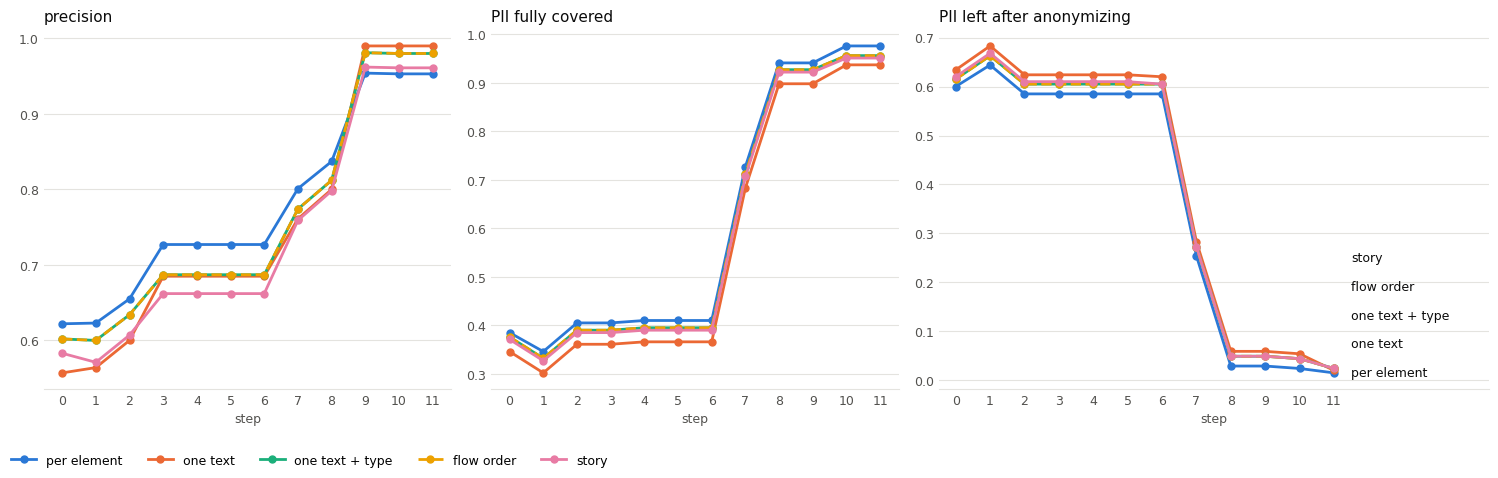

In [8]:
# Categorical slots 1-5 of the reference palette, one per input format; values are also in the tables above
COLORS = dict(zip(FORMATS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PANELS = ["precision", "recall_full", "residual_pii"]

x = range(len(STEPS))
short = [name.split(" ", 1)[0] for name in STEPS]
# each panel has its own y-range (the differences are a few points); the last one is wider for the labels
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.35]})
for ax, metric in zip(axes, PANELS):
    for fmt, color in COLORS.items():
        # flow order coincides with "one text + type": dashed, so both stay visible
        style = "--" if fmt == "flow order" else "-"
        ax.plot(x, table[metric][fmt], color=color, linewidth=2, linestyle=style, marker="o", markersize=5, label=fmt)
    ax.set_title(METRICS[metric], loc="left", fontsize=11, color=INK)
    ax.set_xticks(list(x), short)
    ax.set_xlabel("step", color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# direct labels at the line ends of the last panel, nudged apart when the values are close
ax, metric = axes[-1], PANELS[-1]
low, high = ax.get_ylim()
label_y, prev = {}, low - 1
for fmt in sorted(FORMATS, key=lambda f: table[metric][f].iloc[-1]):
    prev = label_y[fmt] = max(table[metric][fmt].iloc[-1], prev + 0.08 * (high - low))
for fmt in FORMATS:
    ax.annotate(fmt, (len(STEPS) - 1, table[metric][fmt].iloc[-1]), xytext=(len(STEPS) - 0.5, label_y[fmt]),
                textcoords="data", va="center", fontsize=9, color=INK)
ax.set_xlim(-0.5, len(STEPS) + 3.5)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower left", frameon=False, fontsize=9, ncol=len(FORMATS))
fig.tight_layout(rect=(0, 0.07, 1, 1))  # room for the legend below the panels
plt.show()

## Why one text is less precise up to step 8, and more precise from step 9

The false positives per entity type:

In [9]:
pd.DataFrame({
    (name, fmt): runs[fmt, name].detections.loc[lambda d: ~d.tp].entity.value_counts()
    for name in ["8 Belgian recognizers", LAST]
    for fmt in FORMATS
}).fillna(0).astype(int)

8 Belgian recognizers                                            \
                   per element one text one text + type flow order story   
entity                                                                     
LOCATION                    30       48              43         43    43   
PERSON                      10        2               4          4     8   

         11 name parts                                            
           per element one text one text + type flow order story  
entity                                                            
LOCATION             0        0               0          0     0  
PERSON              10        2               4          4     8

In [10]:
d = runs["one text", "8 Belgian recognizers"].detections
d.loc[~d.tp & (d.entity == "LOCATION")].match.value_counts().head(12)

match
Mercurius          4
Plaatsbezoek       3
Aanvragen          3
Testdossier        3
Huwelijksboekje    3
Turnhout           2
Poperinge          2
Risicovol          2
Gedomicilieerd     2
Sint-Niklaas       2
Aalter             2
Hasselt            2
Name: count, dtype: int64

In one text, LOCATION fires more often: a capitalized word at the start of its own line ("Aanvragen.",
"Testdossier", "Mercurius") is taken for a place. PERSON, on the other hand, fires much less often on capitalized
nouns ("Adviezen", "Opgelet"), because they now appear in sentences. Once LOCATION is dropped (step 9), only the
PERSON advantage remains. In the story, the frame words make PERSON fire more often again ("Stap 3: Plaatsbezoek …").

## Why names in short labels are lost

For four labels: what spaCy (the model inside Presidio) makes of the label in each input format at step 11. Only
PERSON counts as a name in the pipeline.

In [11]:
spacy_nl = improved.spacy_model("nl")
labels = {
    "melding-openbaar-domein-hasselt.bpmn": "Tom - Burgerzaken",
    "aanvraag-rijbewijs-tienen.bpmn": "Contact Marleen (+32493276528)",
    "subsidie-vereniging-aalst.bpmn": "Dossier Marleen Jacobs (°04/03/1996)",
    "huwelijk-genk.bpmn": "Doorsturen naar Lander Yilmaz",
}
found = {}
for f, label in labels.items():
    for fmt, switches in FORMATS.items():
        if fmt == "per element":
            text, start = label, 0
        else:
            text, _ = improved.bpmn_document(files[f], replace(STEPS[LAST], **switches))
            start = text.index(label)
        doc = spacy_nl(text)
        ents = [f"{e.text} → {e.label_}" for e in doc.ents if start <= e.start_char and e.end_char <= start + len(label)]
        found[label, fmt] = "; ".join(ents) or "–"
pd.Series(found).unstack()[list(FORMATS)]

,per element,one text,one text + type,flow order,story
Contact Marleen (+32493276528),Marleen → PERSON; +32493276528 → DATE,Contact Marleen → ORG; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE
Doorsturen naar Lander Yilmaz,–,Yilmaz → PERSON,Yilmaz → PERSON,Yilmaz → PERSON,Yilmaz → PERSON
Dossier Marleen Jacobs (°04/03/1996),Marleen Jacobs → PERSON; 04/03/1996 → DATE,Dossier Marleen Jacobs → WORK_OF_ART,Dossier Marleen Jacobs → WORK_OF_ART,Dossier Marleen Jacobs → WORK_OF_ART,Dossier Marleen Jacobs → WORK_OF_ART
Tom - Burgerzaken,Tom - Burgerzaken → PERSON,Tom - Burgerzaken → ORG,Tom - Burgerzaken → WORK_OF_ART,Tom - Burgerzaken → WORK_OF_ART,Tom - Burgerzaken → WORK_OF_ART


In [12]:
# the lines around one of them, in the story
text, _ = improved.bpmn_document(files["melding-openbaar-domein-hasselt.bpmn"], replace(STEPS[LAST], **FORMATS["story"]))
lines = text.splitlines()
i = next(n for n, line in enumerate(lines) if "Tom - Burgerzaken" in line)
print("\n".join(lines[max(0, i - 4) : i + 4]))

Dit proces heet: Melding schade openbaar domein Hasselt.
Externe partij: Melder.
Betrokken in dit proces: Melder.
Betrokken in dit proces: Tom Lemmens.
Betrokken in dit proces: Tom - Burgerzaken.
Het proces begint met: Melding via app of telefoon.
Stap 1: Contact Inge (+32 11 93 64 26).
Opmerking: Navragen bij Ruben.


Inside a text, spaCy still finds the name but gives it another type (ORG, WORK_OF_ART), whatever the order or the
framing. Even directly after "Betrokken in dit proces: Tom Lemmens." (the same person, framed the same way), "Tom -
Burgerzaken" becomes WORK_OF_ART. `nl_core_news_md` is trained on news text and only looks a few words around each
token: the line before is already out of sight, so neither the order of the lines nor a story gives it more context.

## What the one-text formats change at step 11, compared with per element

In [13]:
per_element = runs["per element", LAST]
changes, details = {}, {}
for fmt in [f for f in FORMATS if f != "per element"]:
    r = runs[fmt, LAST]
    d = pii_eval.diff_steps((per_element.spans, per_element.detections), (r.spans, r.detections))
    changes[fmt] = {k: len(v) for k, v in d.items()} | {"crossing_boundary": r.row["crossing_boundary"]}
    details[fmt] = d
pd.DataFrame(changes).T

,pii_gained,pii_lost,fp_removed,fp_added,crossing_boundary
one text,1,8,8,0,0
one text + type,1,4,7,1,0
flow order,1,4,7,1,0
story,1,5,6,4,0


In [14]:
for fmt in ["one text + type", "story"]:
    print(f"=== {fmt}")
    for title in ["pii_lost", "pii_gained", "fp_removed", "fp_added"]:
        if len(details[fmt][title]):
            print(f"--- {title}")
            display(details[fmt][title])

=== one text + type
--- pii_lost


,file,location,entity,value,text
24,omgevingsvergunning-poperinge.bpmn,name,PERSON,Elke Desmet,Elke Desmet
55,subsidie-vereniging-aalst.bpmn,name,PERSON,Marleen Jacobs,Dossier Marleen Jacobs (°04/03/1996)
93,aanvraag-rijbewijs-tienen.bpmn,name,PERSON,Marleen,Contact Marleen (+32493276528)
191,melding-openbaar-domein-hasselt.bpmn,name,PERSON,Tom,Tom - Burgerzaken


--- pii_gained


,file,location,entity,value,text
141,huwelijk-genk.bpmn,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz


--- fp_removed


...

,file,location,entity,value,text
141,huwelijk-genk.bpmn,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz


--- fp_removed


,location,entity,match
4,documentation,PERSON,Opgelet
5,name,PERSON,Plaatsbezoek
8,name,PERSON,OMV_2022098043
10,name,PERSON,Adviezen
11,name,PERSON,Adviezen
13,documentation,PERSON,Opgelet


--- fp_added


,location,entity,match
0,name,PERSON,Plaatsbezoek
2,name,PERSON,Plaatsbezoek
4,name,PERSON,Evenementenloket
7,name,PERSON,Mercurius


Per location and per entity at step 11 (PII fully covered and PII left after anonymizing):

In [15]:
long = pd.concat([r.summary.assign(input_format=fmt) for (fmt, name), r in runs.items() if name == LAST])

def by_format(group, metric):
    return long.loc[long.group == group].pivot(index="scope", columns="input_format", values=metric)[list(FORMATS)]

pd.concat({"recall_full": by_format("location", "recall_full"),
           "residual_pii": by_format("location", "residual_pii")}, axis=1)

recall_full                                             \
input_format  per element one text one text + type flow order  story   
scope                                                                  
documentation       0.968    0.968           0.968      0.968  0.968   
name                0.972    0.899           0.936      0.936  0.927   
text                1.000    1.000           1.000      1.000  1.000   

              residual_pii                                             
input_format   per element one text one text + type flow order  story  
scope                                                                  
documentation        0.032    0.032           0.032      0.032  0.032  
name                 0.009    0.018           0.028      0.028  0.028  
text                 0.000    0.000           0.000      0.000  0.000

In [16]:
pd.concat({"recall_full": by_format("entity", "recall_full"),
           "residual_pii": by_format("entity", "residual_pii")}, axis=1)

recall_full                                             \
input_format  per element one text one text + type flow order  story   
scope                                                                  
ADDRESS             1.000    1.000           1.000      1.000  1.000   
DATE_OF_BIRTH       1.000    1.000           1.000      1.000  1.000   
EMAIL               1.000    1.000           1.000      1.000  1.000   
IBAN                1.000    1.000           1.000      1.000  1.000   
KBO                 1.000    1.000           1.000      1.000  1.000   
LICENSE_PLATE       1.000    1.000           1.000      1.000  1.000   
PERSON              0.947    0.863           0.905      0.905  0.895   
PHONE               1.000    1.000           1.000      1.000  1.000   
RRN                 1.000    1.000           1.000      1.000  1.000   

              residual_pii                                             
input_format   per element one text one text + type flow order  story  
scope                                                                  
ADDRESS              0.000    0.000           0.000      0.000  0.000  
DATE_OF_BIRTH        0.000    0.000           0.000      0.000  0.000  
EMAIL                0.000    0.000           0.000      0.000  0.000  
IBAN                 0.000    0.000           0.000      0.000  0.000  
KBO                  0.000    0.000           0.000      0.000  0.000  
LICENSE_PLATE        0.000    0.000           0.000      0.000  0.000  
PERSON               0.032    0.042           0.053      0.053  0.053  
PHONE                0.000    0.000           0.000      0.000  0.000  
RRN                  0.000    0.000           0.000      0.000  0.000

In [17]:
out = pd.concat([r.summary.assign(input_format=fmt) for (fmt, name), r in runs.items()])
out = out[["input_format", *experiment.SUMMARY_COLUMNS]]
Path("results").mkdir(exist_ok=True)
out.to_csv("results/input_formats.csv", index=False)
print(f"{len(out)} rows -> results/input_formats.csv")

780 rows -> results/input_formats.csv


## Conclusions

At step 11 (all improvements of notebook 01 switched on):

| Input format | Precision | PII fully covered | PII left after anonymizing | False positives | Detection time |
|---|---|---|---|---|---|
| per element | 0.953 | 0.976 | 1.5% | 10 | ≈1.7 s (551 calls) |
| one text | 0.990 | 0.937 | 2.0% | 2 | ≈0.45 s (20 calls) |
| one text + type | 0.980 | 0.956 | 2.4% | 4 | ≈0.5 s (20 calls) |
| flow order | 0.980 | 0.956 | 2.4% | 4 | ≈0.55 s (20 calls) |
| story | 0.961 | 0.951 | 2.4% | 8 | ≈0.65 s (20 calls) |

- **Per element finds the most PII**; one text per diagram is cheaper (one analyzer call per diagram, ≈3–4× faster)
  and gives a shorter, cleaner review list, at the cost of a few names in short labels.
- **Precision of one text depends on LOCATION**: up to step 8 it is less precise than per element (LOCATION fires on
  capitalized words at the start of a line), from step 9 (LOCATION dropped) it is more precise.
- **The element type prefix helps** ("Taak: …"): about 2 points more PII fully covered than plain lines, for 2 more
  false positives.
- **The order of the lines does not matter** (flow order = XML order, in every step), and **framing as a story makes
  it slightly worse** with this model: frame words like "Stap 3:" make a following capitalized word look like a name.
- **Names in short labels are lost because they get another type** (ORG, WORK_OF_ART), whatever the order or framing.
  The spaCy model only looks a few words around each token, so it never reads the diagram as a whole.

**Next steps for the input format**
1. **Hybrid:** one text per diagram, plus a per-element pass only for short labels (pools, lanes, tasks of a few
   words), where the lost names are.
2. **First names:** a recognizer with common first names in Belgium would catch "Tom - Burgerzaken" in every format.
3. **A model that reads the whole document:** a transformer NER model with long context, or an LLM behind a detection
   endpoint, is where a story could pay off; `bpmn_document(..., document_layout="story")` already produces that text
   with offsets that map back to the elements.